In [3]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv("careflow_raw_events_5000_visits.csv")
df

,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41,Emergency,Afternoon,Adult,Doctor_02
...,...,...,...,...,...,...,...
27957,P04999,Discharge,2026-11-04 03:43:30,Emergency,Night,Adult,Discharge_02
27958,P05000,Registration,2026-10-28 14:40:44,Emergency,Afternoon,Adult,Registration_02
27959,P05000,Triage,2026-10-28 14:46:44,Emergency,Afternoon,Adult,Nurse_03
27960,P05000,Doctor Consultation,2026-10-28 14:56:44,Emergency,Afternoon,Adult,Doctor_02


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Work on a copy of your BigQuery DataFrame
df = df.copy()

# Standardize timestamps and sort events
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
df = df.dropna(subset=["case_id", "activity", "timestamp"]).copy()
df["case_id"] = df["case_id"].astype(str)
df["activity"] = df["activity"].astype(str)

df = df.sort_values(["case_id", "timestamp"]).reset_index(drop=True)

# Create previous/next event information
df["previous_activity"] = df.groupby("case_id")["activity"].shift(1)
df["next_activity"] = df.groupby("case_id")["activity"].shift(-1)
df["previous_timestamp"] = df.groupby("case_id")["timestamp"].shift(1)
df["next_timestamp"] = df.groupby("case_id")["timestamp"].shift(-1)

# Elapsed time until the next recorded activity
df["elapsed_minutes"] = (
    df["next_timestamp"] - df["timestamp"]
).dt.total_seconds() / 60

# Transition, e.g. X-Ray → Return to Triage
df["transition"] = (
    df["activity"] + " → " + df["next_activity"].fillna("End of visit")
)

print("Total events:", len(df))
print("Total visits:", df["case_id"].nunique())
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
display(df.head())


Total events: 27962
Total visits: 5000
Date range: 2026-10-05 00:00:02+00:00 to 2026-11-06 01:16:35+00:00


,case_id,activity,timestamp,department,shift,patient_category,resource,previous_activity,next_activity,previous_timestamp,next_timestamp,elapsed_minutes,transition
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02,NaN,Triage,NaT,2026-10-07 20:42:41+00:00,10.0,Registration → Triage
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03,Registration,Lab Test,2026-10-07 20:32:41+00:00,2026-10-07 20:49:41+00:00,7.0,Triage → Lab Test
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02,Triage,Treatment,2026-10-07 20:42:41+00:00,2026-10-07 21:12:41+00:00,23.0,Lab Test → Treatment
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02,Lab Test,Doctor Consultation,2026-10-07 20:49:41+00:00,2026-10-07 21:25:41+00:00,13.0,Treatment → Doctor Consultation
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02,Treatment,Discharge,2026-10-07 21:12:41+00:00,2026-10-07 21:32:41+00:00,7.0,Doctor Consultation → Discharge


In [7]:
#Data quality checks

# Missing values in each column
missing_summary = df.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(df) * 100
)
display(missing_summary)

# Duplicate event records
duplicate_count = df.duplicated(
    subset=["case_id", "activity", "timestamp"]
).sum()
print("Duplicate case/activity/timestamp records:", duplicate_count)

# Negative time intervals between consecutive events
negative_intervals = df[df["elapsed_minutes"] < 0]
print("Negative transition intervals:", len(negative_intervals))

# Events per visit
events_per_visit = df.groupby("case_id").size().rename("event_count")
display(events_per_visit.describe().to_frame())

# Visits with more than 8 events: inspect rather than automatically delete
print("Visits with more than 8 events:", (events_per_visit > 8).sum())


,missing_count,missing_pct
case_id,0,0.00000
activity,0,0.00000
timestamp,0,0.00000
department,0,0.00000
shift,0,0.00000
patient_category,0,0.00000
resource,0,0.00000
previous_activity,5000,17.88141
next_activity,5000,17.88141
previous_timestamp,5000,17.88141


Duplicate case/activity/timestamp records: 0
Negative transition intervals: 0


,event_count
count,5000.000000
mean,5.592400
std,1.248749
min,4.000000
25%,5.000000
50%,5.000000
75%,6.000000
max,8.000000


Visits with more than 8 events: 0


In [8]:
#Main project KPIs

total_visits = df["case_id"].nunique()
total_events = len(df)

return_ids = set(
    df.loc[df["activity"].eq("Return to Triage"), "case_id"].unique()
)

returned_visits = len(return_ids)
return_rate = returned_visits / total_visits * 100 if total_visits else 0

activity_counts = df["activity"].value_counts()
activity_summary = activity_counts.rename_axis("activity").reset_index(
    name="event_count"
)
activity_summary["pct_of_all_events"] = (
    activity_summary["event_count"] / total_events * 100
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total visits",
        "Total recorded events",
        "Visits with Return to Triage",
        "Return-to-triage rate (%)",
        "Average events per visit",
        "Median events per visit"
    ],
    "Value": [
        total_visits,
        total_events,
        returned_visits,
        round(return_rate, 2),
        round(events_per_visit.mean(), 2),
        round(events_per_visit.median(), 2)
    ]
})

display(kpi_summary)
display(activity_summary)


,KPI,Value
0,Total visits,5000.00
1,Total recorded events,27962.00
2,Visits with Return to Triage,1141.00
3,Return-to-triage rate (%),22.82
4,Average events per visit,5.59
5,Median events per visit,5.00


,activity,event_count,pct_of_all_events
0,Triage,6141,21.961948
1,Registration,5000,17.881410
2,Doctor Consultation,5000,17.881410
3,Discharge,4601,16.454474
4,X-Ray,2815,10.067234
5,Lab Test,1476,5.278592
6,Treatment,1389,4.967456
7,Return to Triage,1141,4.080538
8,Admission,399,1.426937


In [10]:
#Return-to-triage analysis
# A. Return-to-triage events and visit-level rate
return_events = df[df["activity"].eq("Return to Triage")].copy()

print("Return-to-triage events:", len(return_events))
print("Distinct visits with a return:", return_events["case_id"].nunique())
print(
    "Visit-level return rate:",
    round(return_events["case_id"].nunique() / total_visits * 100, 2),
    "%"
)

# B. Activity immediately before each return
print("\nActivity immediately before Return to Triage:")
display(
    return_events["previous_activity"]
    .fillna("No previous activity")
    .value_counts()
    .rename_axis("previous_activity")
    .reset_index(name="return_events")
)

# C. Activity immediately after each return
print("\nActivity immediately after Return to Triage:")
display(
    return_events["next_activity"]
    .fillna("End of visit")
    .value_counts()
    .rename_axis("next_activity")
    .reset_index(name="return_events")
)

# D. Check the specific X-Ray → Return to Triage transition
xray_returns = df[
    df["activity"].eq("X-Ray")
    & df["next_activity"].eq("Return to Triage")
]

print("\nX-Ray → Return to Triage transitions:", len(xray_returns))

# E. Visit-level return flag
visit_return_flag = (
    df.groupby("case_id")["activity"]
    .apply(lambda activities: activities.eq("Return to Triage").any())
    .rename("returned_to_triage")
)

print("\nVisit-level return flag:")
display(visit_return_flag.value_counts().rename_axis("returned_to_triage").to_frame("visits"))


Return-to-triage events: 1141
Distinct visits with a return: 1141
Visit-level return rate: 22.82 %

Activity immediately before Return to Triage:


,previous_activity,return_events
0,X-Ray,1141



Activity immediately after Return to Triage:


,next_activity,return_events
0,Triage,1141



X-Ray → Return to Triage transitions: 1141

Visit-level return flag:


,visits
returned_to_triage,
False,3859
True,1141


In [11]:
#Visit duration analysis

visit_summary = (
    df.groupby("case_id")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        event_count=("activity", "size"),
        shift=("shift", "first"),
        patient_category=("patient_category", "first")
    )
    .reset_index()
)

visit_summary["duration_minutes"] = (
    visit_summary["end_time"] - visit_summary["start_time"]
).dt.total_seconds() / 60

visit_summary["returned_to_triage"] = (
    visit_summary["case_id"].isin(return_ids)
)

# Overall duration distribution
display(visit_summary["duration_minutes"].describe().to_frame("duration_minutes"))

# Compare visits with and without a return
duration_comparison = (
    visit_summary.groupby("returned_to_triage")["duration_minutes"]
    .agg(
        visit_count="count",
        mean_minutes="mean",
        median_minutes="median",
        min_minutes="min",
        max_minutes="max"
    )
    .round(2)
)

display(duration_comparison)

# Difference between the two groups
duration_means = visit_summary.groupby("returned_to_triage")["duration_minutes"].mean()
if True in duration_means.index and False in duration_means.index:
    mean_difference = duration_means.loc[True] - duration_means.loc[False]
    print("Mean duration difference (return minus no return):",
          round(mean_difference, 2), "minutes")


,duration_minutes
count,5000.000000
mean,80.233000
std,28.333155
min,16.000000
25%,60.000000
50%,78.000000
75%,98.000000
max,201.000000


,visit_count,mean_minutes,median_minutes,min_minutes,max_minutes
returned_to_triage,,,,,
False,3859,72.09,70.0,16.0,174.0
True,1141,107.78,106.0,49.0,201.0


Mean duration difference (return minus no return): 35.69 minutes


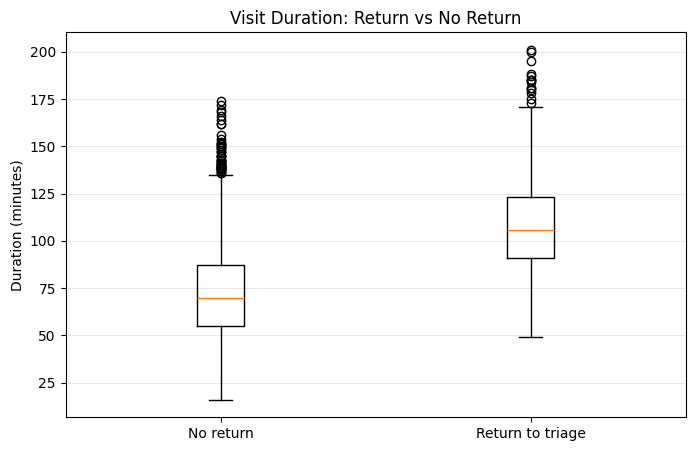

In [12]:
#Plot: visit duration with and without return

duration_groups = [
    visit_summary.loc[
        ~visit_summary["returned_to_triage"], "duration_minutes"
    ],
    visit_summary.loc[
        visit_summary["returned_to_triage"], "duration_minutes"
    ]
]

plt.figure(figsize=(8, 5))
plt.boxplot(duration_groups, tick_labels=["No return", "Return to triage"])
plt.title("Visit Duration: Return vs No Return")
plt.ylabel("Duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [15]:
#Shift-wise analysis

shift_summary = (
    visit_summary.groupby("shift", dropna=False)
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration_minutes=("duration_minutes", "mean"),
        median_duration_minutes=("duration_minutes", "median")
    )
    .reset_index()
)

shift_summary["return_rate_pct"] = (
    shift_summary["return_visits"] / shift_summary["total_visits"] * 100
).round(2)

shift_summary = shift_summary.round({
    "mean_duration_minutes": 2,
    "median_duration_minutes": 2
})

display(shift_summary.sort_values("return_rate_pct", ascending=False))



,shift,total_visits,return_visits,mean_duration_minutes,median_duration_minutes,return_rate_pct
0,Afternoon,1627,393,80.80,78.0,24.15
1,Morning,1677,383,80.27,78.0,22.84
2,Night,1696,365,79.65,77.0,21.52


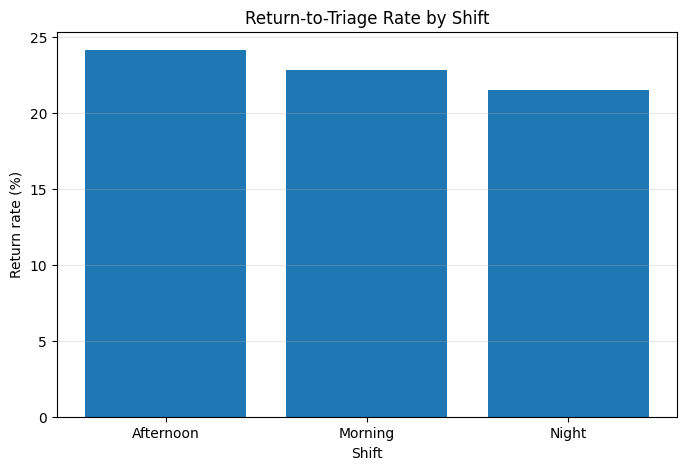

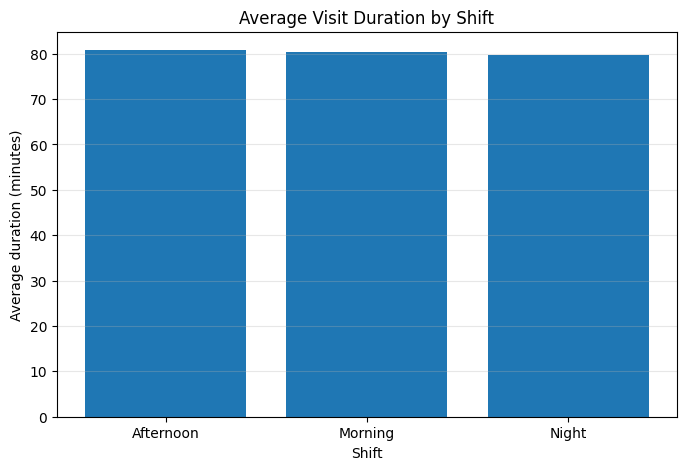

In [16]:

# Shift-wise return rate
plot_data = shift_summary.sort_values("shift")

plt.figure(figsize=(8, 5))
plt.bar(plot_data["shift"].astype(str), plot_data["return_rate_pct"])
plt.title("Return-to-Triage Rate by Shift")
plt.xlabel("Shift")
plt.ylabel("Return rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Shift-wise average visit duration
plt.figure(figsize=(8, 5))
plt.bar(
    plot_data["shift"].astype(str),
    plot_data["mean_duration_minutes"]
)
plt.title("Average Visit Duration by Shift")
plt.xlabel("Shift")
plt.ylabel("Average duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.show()
